# Atelier — Machine Learning : Pokémon

# Partie 1 — Préparation des données

# Données du pokedex

In [1]:
import numpy as np
import pandas as pd

pd.set_option('display.max_columns', None)  # Show all columns
pd.set_option('future.no_silent_downcasting', True)

/tmp/ipykernel_5542/795208566.py:5: Pandas4Warning: 'future.no_silent_downcasting' is deprecated, please refrain from using it.
  pd.set_option('future.no_silent_downcasting', True)


## Charger les données

In [2]:
nosPokemons = pd.read_csv("data/pokedex.csv")

#Affichage des colonnes du Dataframe
print(nosPokemons.columns.values)

<StringArray>
[                 'NUMERO',                     'NOM',
                  'TYPE_1',                  'TYPE_2',
           'POINTS_DE_VIE',          'NIVEAU_ATTAQUE',
          'NIVEAU_DEFENSE', 'NIVEAU_ATTAQUE_SPECIALE',
 'NIVEAU_DEFENSE_SPECIALE',                 'VITESSE',
      'NOMBRE_GENERATIONS',              'LEGENDAIRE']
Length: 12, dtype: str


## Afficher les dix premières lignes

In [3]:
print(nosPokemons.head(10))

   NUMERO               NOM TYPE_1  TYPE_2  POINTS_DE_VIE  NIVEAU_ATTAQUE  \
0       1        Bulbizarre  Herbe  Poison             45              49   
1       2        Herbizarre  Herbe  Poison             60              62   
2       3        Florizarre  Herbe  Poison             80              82   
3       4   Mega Florizarre  Herbe  Poison             80             100   
4       5         Salameche    Feu     NaN             39              52   
5       6         Reptincel    Feu     NaN             58              64   
6       7         Dracaufeu    Feu     Vol             78              84   
7       8  Mega Dracaufeu X    Feu  Dragon             78             130   
8       9  Mega Dracaufeu Y    Feu     Vol             78             104   
9      10          Carapuce    Eau     NaN             44              48   

   NIVEAU_DEFENSE  NIVEAU_ATTAQUE_SPECIALE  NIVEAU_DEFENSE_SPECIALE  VITESSE  \
0              49                       65                       65     

## Feature LEGENDAIRE

In [4]:
# remplacement de VRAI FAUX par 1 0
nosPokemonsClean = nosPokemons.copy()
nosPokemonsClean["LEGENDAIRE"] = nosPokemonsClean["LEGENDAIRE"].replace({"VRAI": 1, "FAUX": 0}).astype(int)
print(nosPokemonsClean.head())

   NUMERO              NOM TYPE_1  TYPE_2  POINTS_DE_VIE  NIVEAU_ATTAQUE  \
0       1       Bulbizarre  Herbe  Poison             45              49   
1       2       Herbizarre  Herbe  Poison             60              62   
2       3       Florizarre  Herbe  Poison             80              82   
3       4  Mega Florizarre  Herbe  Poison             80             100   
4       5        Salameche    Feu     NaN             39              52   

   NIVEAU_DEFENSE  NIVEAU_ATTAQUE_SPECIALE  NIVEAU_DEFENSE_SPECIALE  VITESSE  \
0              49                       65                       65       45   
1              63                       80                       80       60   
2              83                      100                      100       80   
3             123                      122                      120       80   
4              43                       60                       50       65   

   NOMBRE_GENERATIONS  LEGENDAIRE  
0                   1     

## Nombre d'observations

In [5]:
#Comptage du nombre d'observations et de features
print(nosPokemonsClean.shape)

(800, 12)


In [6]:
#Informations sur notre jeu de données
nosPokemonsClean.info()

<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 12 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   NUMERO                   800 non-null    int64
 1   NOM                      799 non-null    str  
 2   TYPE_1                   800 non-null    str  
 3   TYPE_2                   413 non-null    str  
 4   POINTS_DE_VIE            800 non-null    int64
 5   NIVEAU_ATTAQUE           800 non-null    int64
 6   NIVEAU_DEFENSE           800 non-null    int64
 7   NIVEAU_ATTAQUE_SPECIALE  800 non-null    int64
 8   NIVEAU_DEFENSE_SPECIALE  800 non-null    int64
 9   VITESSE                  800 non-null    int64
 10  NOMBRE_GENERATIONS       800 non-null    int64
 11  LEGENDAIRE               800 non-null    int64
dtypes: int64(9), str(3)
memory usage: 75.1 KB


## Retrouver le nom manquant

In [7]:
print(nosPokemonsClean[nosPokemonsClean['NOM'].isnull()])

    NUMERO  NOM  TYPE_1 TYPE_2  POINTS_DE_VIE  NIVEAU_ATTAQUE  NIVEAU_DEFENSE  \
62      63  NaN  Combat    NaN             65             105              60   

    NIVEAU_ATTAQUE_SPECIALE  NIVEAU_DEFENSE_SPECIALE  VITESSE  \
62                       60                       70       95   

    NOMBRE_GENERATIONS  LEGENDAIRE  
62                   1           0  


In [8]:
print(nosPokemonsClean['NOM'][61])
print(nosPokemonsClean['NOM'][63])

Ferosinge
Caninos


In [9]:
nosPokemonsClean.loc[62, 'NOM'] = 'Colossinge'

In [10]:
print(nosPokemonsClean['NOM'][62])

Colossinge


# Données de combats

## Lecture des données de combats

In [11]:
#Chargement des données des combats
combats = pd.read_csv("data/combats.csv")

#Affichage des colonnes du Dataframe
print(combats.columns.values)

#Affichage des 10 premières lignes du Dataframe
print(combats.head(10))

#Comptage du nombre de lignes et de colonnes
print(combats.shape)

#Informations sur notre jeu de données
combats.info()

<StringArray>
['Premier_Pokemon', 'Second_Pokemon', 'Pokemon_Gagnant']
Length: 3, dtype: str
   Premier_Pokemon  Second_Pokemon  Pokemon_Gagnant
0              266             298              298
1              702             701              701
2              191             668              668
3              237             683              683
4              151             231              151
5              657             752              657
6              192             134              134
7               73             545              545
8              220             763              763
9              302              31               31
(50000, 3)
<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 3 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   Premier_Pokemon  50000 non-null  int64
 1   Second_Pokemon   50000 non-null  int64
 2   Pokemon_Gagnant  50000 non-null  int64
dtypes:

## Nombre de combats menés

In [12]:
nbFoisPremierePosition = combats.groupby('Premier_Pokemon').size()
print(nbFoisPremierePosition)

Premier_Pokemon
1      70
2      55
3      68
4      62
5      50
       ..
796    49
797    64
798    60
799    75
800    61
Length: 784, dtype: int64


In [13]:
nbFoisSecondePosition = combats.groupby('Second_Pokemon').size()
print(nbFoisSecondePosition)

Second_Pokemon
1      63
2      66
3      64
4      63
5      62
       ..
796    56
797    67
798    59
799    69
800    60
Length: 784, dtype: int64


In [14]:
nombreTotalDeCombats = nbFoisPremierePosition.add(nbFoisSecondePosition, fill_value=0)
print(nombreTotalDeCombats)

Premier_Pokemon
1      133
2      121
3      132
4      125
5      112
      ... 
796    105
797    131
798    119
799    144
800    121
Length: 784, dtype: int64


## Nombre de combats gagnés

In [15]:
nombreDeVictoires = combats.groupby('Pokemon_Gagnant').size()
print(nombreDeVictoires)

Pokemon_Gagnant
1       37
2       46
3       89
4       70
5       55
      ... 
796     39
797    116
798     60
799     89
800     75
Length: 783, dtype: int64


## Assemblage des observations

In [16]:
listeAAgreger = pd.DataFrame(index=nombreTotalDeCombats.index)

#On ajoute le nombre de combats
listeAAgreger['NBR_COMBATS'] = nombreTotalDeCombats

#On ajoute le nombre de victoires
listeAAgreger['NBR_VICTOIRES'] = nombreDeVictoires

#On calcule le pourcentage de victoires
listeAAgreger['POURCENTAGE_DE_VICTOIRES'] = listeAAgreger['NBR_VICTOIRES'] / listeAAgreger['NBR_COMBATS']

#On affiche la nouvelle liste
print(listeAAgreger)

                 NBR_COMBATS  NBR_VICTOIRES  POURCENTAGE_DE_VICTOIRES
Premier_Pokemon                                                      
1                        133           37.0                  0.278195
2                        121           46.0                  0.380165
3                        132           89.0                  0.674242
4                        125           70.0                  0.560000
5                        112           55.0                  0.491071
...                      ...            ...                       ...
796                      105           39.0                  0.371429
797                      131          116.0                  0.885496
798                      119           60.0                  0.504202
799                      144           89.0                  0.618056
800                      121           75.0                  0.619835

[784 rows x 3 columns]


In [17]:
nouveauPokedex = nosPokemonsClean.merge(listeAAgreger, left_on='NUMERO', right_index=True, how='left')
print(nouveauPokedex.describe())

         NUMERO  POINTS_DE_VIE  NIVEAU_ATTAQUE  NIVEAU_DEFENSE  \
count  800.0000     800.000000      800.000000      800.000000   
mean   400.5000      69.258750       79.001250       73.842500   
std    231.0844      25.534669       32.457366       31.183501   
min      1.0000       1.000000        5.000000        5.000000   
25%    200.7500      50.000000       55.000000       50.000000   
50%    400.5000      65.000000       75.000000       70.000000   
75%    600.2500      80.000000      100.000000       90.000000   
max    800.0000     255.000000      190.000000      230.000000   

       NIVEAU_ATTAQUE_SPECIALE  NIVEAU_DEFENSE_SPECIALE     VITESSE  \
count               800.000000               800.000000  800.000000   
mean                 72.820000                71.902500   68.277500   
std                  32.722294                27.828916   29.060474   
min                  10.000000                20.000000    5.000000   
25%                  49.750000                50.0

# Partie 2 — Analyse des données

## Description du jeu d'observations

In [18]:
print(nouveauPokedex.describe())

         NUMERO  POINTS_DE_VIE  NIVEAU_ATTAQUE  NIVEAU_DEFENSE  \
count  800.0000     800.000000      800.000000      800.000000   
mean   400.5000      69.258750       79.001250       73.842500   
std    231.0844      25.534669       32.457366       31.183501   
min      1.0000       1.000000        5.000000        5.000000   
25%    200.7500      50.000000       55.000000       50.000000   
50%    400.5000      65.000000       75.000000       70.000000   
75%    600.2500      80.000000      100.000000       90.000000   
max    800.0000     255.000000      190.000000      230.000000   

       NIVEAU_ATTAQUE_SPECIALE  NIVEAU_DEFENSE_SPECIALE     VITESSE  \
count               800.000000               800.000000  800.000000   
mean                 72.820000                71.902500   68.277500   
std                  32.722294                27.828916   29.060474   
min                  10.000000                20.000000    5.000000   
25%                  49.750000                50.0

## Types de Pokémons

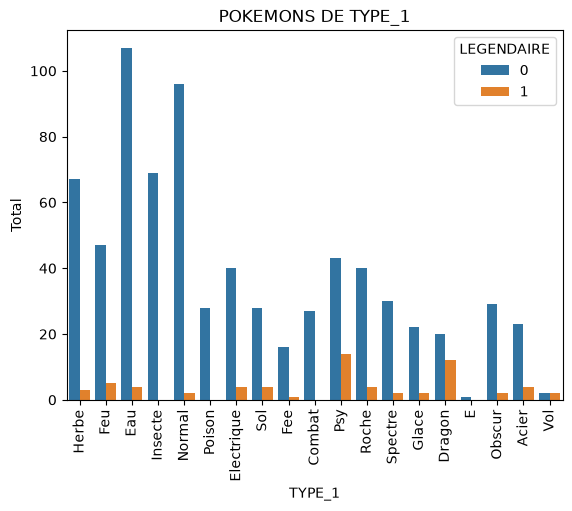

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

axe_X = sns.countplot(x="TYPE_1", hue="LEGENDAIRE", data=nouveauPokedex)
plt.xticks(rotation=90)
plt.xlabel('TYPE_1')
plt.ylabel('Total')
plt.title("POKEMONS DE TYPE_1")
plt.show()

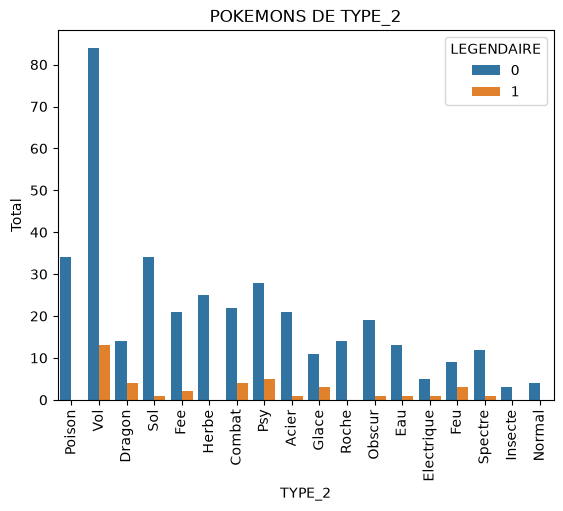

In [20]:
axe_X = sns.countplot(x="TYPE_2", hue="LEGENDAIRE", data=nouveauPokedex)
plt.xticks(rotation=90)
plt.xlabel('TYPE_2')
plt.ylabel('Total')
plt.title("POKEMONS DE TYPE_2")
plt.show()

## Types gagnants et perdants

In [21]:
moyenneVictoiresParType = nouveauPokedex.groupby('TYPE_1').agg({"POURCENTAGE_DE_VICTOIRES": "mean"}).sort_values(by="POURCENTAGE_DE_VICTOIRES")
print(moyenneVictoiresParType)

            POURCENTAGE_DE_VICTOIRES
TYPE_1                              
Fee                         0.329300
E                           0.343750
Roche                       0.404852
Acier                       0.424529
Poison                      0.433262
Insecte                     0.439006
Glace                       0.439604
Herbe                       0.440364
Eau                         0.470520
Combat                      0.475616
Spectre                     0.484027
Normal                      0.535578
Sol                         0.541526
Psy                         0.545747
Feu                         0.579215
Obscur                      0.629726
Electrique                  0.632861
Dragon                      0.633587
Vol                         0.765061


## Corrélation entre les données

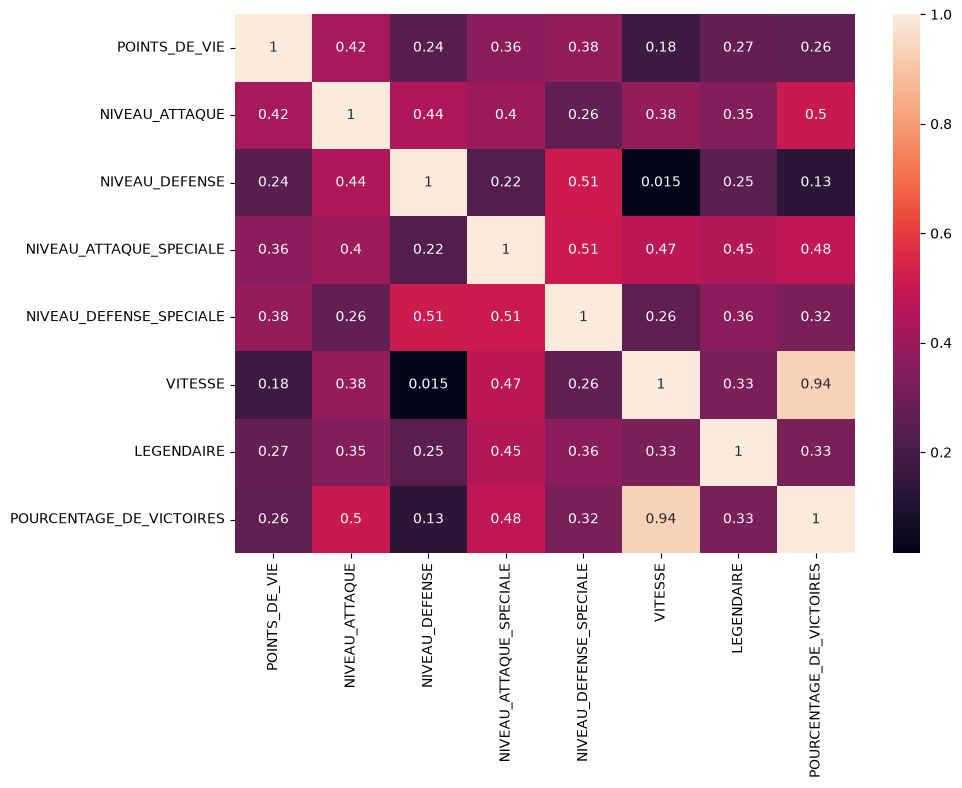

In [22]:
corr = nouveauPokedex.loc[:, ['POINTS_DE_VIE', 'NIVEAU_ATTAQUE',
    'NIVEAU_DEFENSE', 'NIVEAU_ATTAQUE_SPECIALE', 'NIVEAU_DEFENSE_SPECIALE',
    'VITESSE', 'LEGENDAIRE', 'POURCENTAGE_DE_VICTOIRES']].corr()

plt.figure(figsize=(10, 7))
sns.heatmap(corr, xticklabels=corr.columns, yticklabels=corr.columns, annot=True)
plt.show()

## Vérification des hypothèses

In [23]:
#Combats proposés dans l'atelier : premier, second, gagnant
combatsAVerifier = [(155, 321, 155), (101, 583, 583), (404, 32, 32)]

for premier, second, gagnant in combatsAVerifier:
    pokemons = nosPokemonsClean.set_index('NUMERO').loc[[premier, second], ['NOM', 'NIVEAU_ATTAQUE', 'VITESSE']]
    print(f"Combat {premier} contre {second} - gagnant : {gagnant}")
    print(pokemons)
    print()

Combat 155 contre 321 - gagnant : 155
               NOM  NIVEAU_ATTAQUE  VITESSE
NUMERO                                     
155     Mega Ptera             135      150
321       Makuhita              60       25

Combat 101 contre 583 - gagnant : 583
             NOM  NIVEAU_ATTAQUE  VITESSE
NUMERO                                   
101     Spectrum              50       95
583      Zeblitz             100      116

Combat 404 contre 32 - gagnant : 32
             NOM  NIVEAU_ATTAQUE  VITESSE
NUMERO                                   
404     Rosabyss              84       52
32        Raichu              90      110



## Sauvegarde du dataset

In [24]:
#Sauvegarde du Dataframe Pokedex
dataset = nouveauPokedex
dataset.to_csv("data/dataset.csv", sep='\t', index=False)
print(dataset.shape)

(800, 15)
